# Bài 10: Mạng Tích chập (CNN) Từ Đầu — Giải phẫu Conv2d, Pooling, BatchNorm, Residual và Receptive Field

## 1. Mục tiêu học tập
- Hiểu vì sao **CNN (`Convolutional Neural Network`)** vượt trội hơn `MLP` trên ảnh nhờ 2 nguyên lý: **Kết nối cục bộ (`Local Connectivity`)** và **Chia sẻ trọng số (`Weight Sharing`)**.
- Nắm vững ý nghĩa và công thức tính kích thước của mọi thành phần trong CNN:
  - `nn.Conv2d`: `in_channels`, `out_channels`, `kernel_size`, `stride`, `padding`, `dilation`, `groups`.
  - `Pooling`: `MaxPool2d`, `AvgPool2d`, và sự khác biệt giữa `Flatten` với **`Global Average Pooling` (`AdaptiveAvgPool2d(1)`)**.
  - Chuẩn hóa bên trong mạng: `BatchNorm2d` so với `LayerNorm`.
  - Điều chuẩn: `Dropout`.
  - Kết nối tắt phần dư: **`Residual Connection`** ($y = \mathcal{F}(x) + x$).
  - Vùng cảm nhận hiệu dụng: **`Receptive Field`**.
- Giải thích rõ: **Vì sao mỗi lớp được chọn và điều gì xảy ra nếu bỏ hoặc thay nó?**
- Huấn luyện thực tế `SimpleCNN` và `ResidualCNN`, lưu checkpoint và kiểm chứng kết quả.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 09.

## 3. Thời gian học dự kiến
- Khoảng **3.0 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Ở Bài 09, mạng `SimpleMLP` tốn hơn `401,000` tham số cho ảnh `32x32x3`. Trong bài này, chúng ta xây dựng `SimpleCNN` chỉ với `~24,000` tham số (nhỏ hơn **16 lần**!) nhưng đạt độ chính xác phân loại cao hơn hẳn và bền vững khi vật thể dịch chuyển vị trí trong ảnh.

## 5. Giải thích trực quan: Vì sao cần từng lớp và Điều gì xảy ra nếu bỏ nó?
| Thành phần trong khối CNN | Lý do được chọn | Điều gì xảy ra nếu BỎ hoặc THAY ĐỔI nó? |
|---|---|---|
| **`nn.Conv2d(C_in, C_out, K, S, P)`** | Trượt `C_out` bộ lọc cục bộ `KxK` khắp ảnh để phát hiện cạnh, góc, hình dạng ở mọi vị trí. | Nếu thay bằng `Linear`, số tham số tăng hàng chục lần và mất hoàn toàn cấu trúc lân cận 2D. |
| **`nn.BatchNorm2d(C_out)`** | Chuẩn hóa từng kênh về trung bình `0`, phương sai `1` trên mỗi mini-batch rồi nhân $\gamma$, cộng $\beta$. | **Nếu bỏ `BatchNorm2d`**: Các mạng sâu hội tụ chậm hơn nhiều, nhạy cảm với `learning_rate` lớn và dễ bị bão hòa/triệt tiêu đạo hàm. |
| **`nn.ReLU(inplace=True)`** | Khử tuyến tính các giá trị âm về `0`. | **Nếu bỏ `ReLU`**: Chuỗi nhiều tầng `Conv2d` liên tiếp thu gọn thành 1 phép lọc tuyến tính duy nhất! |
| **`nn.MaxPool2d(2, 2)`** (hoặc `Conv2d(..., stride=2)`) | Giảm một nửa chiều cao và chiều rộng ($H/2, W/2$), giúp các tầng sau có **`Receptive Field`** rộng hơn để nhìn tổng thể vật thể. | **Nếu bỏ toàn bộ bước giảm độ phân giải**: Bộ nhớ trung gian (`feature maps`) rất nặng và vùng nhìn hiệu dụng (`Receptive Field`) ở tầng cuối quá hẹp, không bao quát được vật thể lớn. |
| **`nn.AdaptiveAvgPool2d((1, 1))`** (Global Average Pooling) | Lấy trung bình mỗi bản đồ đặc trưng `(C, H, W)` thành đúng 1 con số `(C, 1, 1)` trước khi vào tầng phân loại `Linear`. | Nếu dùng `Flatten` trực tiếp mà không qua Global Average Pooling, tầng `Linear` cuối sẽ phình to gấp hàng chục lần và bắt buộc ảnh đầu vào phải cố định kích thước. |
| **`Residual Connection` ($y = \mathcal{F}(x) + x$)** | Cộng trực tiếp đầu vào khối vào đầu ra khối. | Khi mạng có từ 15–20 tầng trở lên, nếu không có nhánh cộng tắt này, đạo hàm truyền ngược bị suy giảm khiến mạng sâu hơn lại có `train_loss` tệ hơn mạng nông! |

## 6 & 7. Công thức Tính Kích thước Đầu ra & Vùng Cảm nhận (`Receptive Field`)
1. **Kích thước chiều cao/rộng sau tầng `Conv2d` hoặc `Pool2d`**:
   $$H_{\text{out}} = \left\lfloor \frac{H_{\text{in}} + 2P - D \times (K - 1) - 1}{S} + 1 \right\rfloor$$
   - **Ví dụ số nhỏ**: Ảnh $H_{\text{in}} = 32$, dùng `Conv2d(kernel_size=3, stride=1, padding=1, dilation=1)`:
     $$H_{\text{out}} = \left\lfloor \frac{32 + 2(1) - 1(3 - 1) - 1}{1} + 1 \right\rfloor = 32 \quad (\text{Giữ nguyên kích thước!})$$
2. **Số lượng tham số của 1 tầng `Conv2d`**:
   $$\text{Params}_{\text{Conv2d}} = C_{\text{out}} \times \left(\frac{C_{\text{in}}}{\text{groups}} \times K_H \times K_W\right) + \text{ (} C_{\text{out}} \text{ nếu có bias)}$$


In [1]:
# Cell 1: Kiểm tra Công thức Shape, Receptive Field và Bảng Tham số của SimpleCNN vs ResidualCNN
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

from src.utils import (
    set_seed,
    get_device,
    count_parameters,
    summarize_model_layers,
)
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.models import SimpleCNN, ResidualCNN
from src.training import fit_classifier, evaluate_classifier
from src.evaluation import compute_classification_metrics

QUICK_RUN = True
set_seed(42)
device = get_device()


def compute_receptive_field(layers_cfg: list[tuple[str, int, int, int]]) -> pd.DataFrame:
    """
    Tính vùng cảm nhận (Receptive Field R) và bước nhảy tích lũy (jump j) qua từng tầng.
    Mỗi phần tử trong layers_cfg là: (name, kernel_size K, stride S, dilation D).
    """
    r_curr = 1
    j_curr = 1
    rows = []
    for name, k, s, d in layers_cfg:
        r_curr = r_curr + (k - 1) * d * j_curr
        j_curr = j_curr * s
        rows.append({"Layer": name, "Kernel": k, "Stride": s, "Dilation": d, "Jump_Stride": j_curr, "Receptive_Field": f"{r_curr}x{r_curr}"})
    return pd.DataFrame(rows)


rf_df = compute_receptive_field([
    ("Conv1 (3x3, s=1)", 3, 1, 1),
    ("MaxPool1 (2x2, s=2)", 2, 2, 1),
    ("Conv2 (3x3, s=1)", 3, 1, 1),
    ("MaxPool2 (2x2, s=2)", 2, 2, 1),
    ("Conv3 (3x3, s=1)", 3, 1, 1),
])
print("=== BẢNG TÍNH VÙNG CẢM NHẬN (RECEPTIVE FIELD) QUA TỪNG TẦNG CỦA SIMPLE_CNN ===")
print(rf_df.to_string(index=False))

cnn_model = SimpleCNN(in_channels=3, num_classes=4, base_channels=16).to(device)
res_model = ResidualCNN(in_channels=3, num_classes=4, base_channels=16).to(device)
print(f"\nSimpleCNN parameters  : {count_parameters(cnn_model)}")
print(f"ResidualCNN parameters: {count_parameters(res_model)}")

cnn_summary_df = pd.DataFrame(summarize_model_layers(cnn_model, input_shape=(1, 3, 32, 32), device=device))
print("\n=== BẢNG LAYER SUMMARY CỦA SIMPLE_CNN ===")
print(cnn_summary_df.to_string(index=False))


=== BẢNG TÍNH VÙNG CẢM NHẬN (RECEPTIVE FIELD) QUA TỪNG TẦNG CỦA SIMPLE_CNN ===
              Layer  Kernel  Stride  Dilation  Jump_Stride Receptive_Field
   Conv1 (3x3, s=1)       3       1         1            1             3x3
MaxPool1 (2x2, s=2)       2       2         1            2             4x4
   Conv2 (3x3, s=1)       3       1         1            2             8x8
MaxPool2 (2x2, s=2)       2       2         1            4           10x10
   Conv3 (3x3, s=1)       3       1         1            4           18x18

SimpleCNN parameters  : {'total': 23956, 'trainable': 23956, 'frozen': 0}
ResidualCNN parameters: {'total': 77652, 'trainable': 77652, 'frozen': 0}

=== BẢNG LAYER SUMMARY CỦA SIMPLE_CNN ===
 layer_name        layer_type    output_shape  total_params  trainable_params
 features.0            Conv2d (1, 16, 32, 32)           432               432
 features.1       BatchNorm2d (1, 16, 32, 32)            32                32
 features.2              ReLU (1, 16, 32, 32)

In [2]:
# Cell 2: Huấn luyện Thực tế SimpleCNN và ResidualCNN, Lưu Checkpoint Tốt nhất
n_samples = 280 if QUICK_RUN else 560
ds = generate_synthetic_shapes_dataset(num_samples=n_samples, image_size=32, seed=42, noise_std=10.0)
images_np, labels_np, class_names = ds["images"], ds["labels"], ds["class_names"]

idx_all = np.arange(len(images_np))
idx_tr, idx_temp = train_test_split(idx_all, test_size=0.30, random_state=42, stratify=labels_np)
idx_va, idx_te = train_test_split(idx_temp, test_size=0.50, random_state=42, stratify=labels_np[idx_temp])

X_all_t = torch.from_numpy(images_np).permute(0, 3, 1, 2).float() / 255.0
y_all_t = torch.from_numpy(labels_np).long()

tr_mean = X_all_t[idx_tr].mean(dim=(0, 2, 3), keepdim=True)
tr_std = X_all_t[idx_tr].std(dim=(0, 2, 3), keepdim=True) + 1e-6
X_norm = (X_all_t - tr_mean) / tr_std

train_loader = DataLoader(TensorDataset(X_norm[idx_tr], y_all_t[idx_tr]), batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(TensorDataset(X_norm[idx_va], y_all_t[idx_va]), batch_size=32, shuffle=False, num_workers=0)
test_loader = DataLoader(TensorDataset(X_norm[idx_te], y_all_t[idx_te]), batch_size=32, shuffle=False, num_workers=0)

ckpt_cnn = project_root / "outputs" / "checkpoints" / "nb10_simple_cnn_best.pt"
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(cnn_model.parameters(), lr=2e-3, weight_decay=1e-4)

history_cnn = fit_classifier(
    model=cnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=12 if QUICK_RUN else 25,
    patience=6,
    checkpoint_path=ckpt_cnn,
    class_names=class_names,
    preprocessing_config={"image_size": 32, "mean": tr_mean.squeeze().tolist(), "std": tr_std.squeeze().tolist()},
)

test_res, y_te_true, y_te_pred, y_te_prob = evaluate_classifier(cnn_model, test_loader, criterion, device)
test_metrics = compute_classification_metrics(y_te_true, y_te_pred, class_names)
print(f"SimpleCNN Best Epoch: {history_cnn['best_epoch']} | Best Val Acc: {history_cnn['best_val_acc']*100:.1f}%")
print(f"SimpleCNN Test Accuracy: {test_metrics['accuracy']*100:.1f}% | Test Macro-F1: {test_metrics['macro_f1']:.3f}")


SimpleCNN Best Epoch: 11 | Best Val Acc: 83.3%
SimpleCNN Test Accuracy: 81.0% | Test Macro-F1: 0.800


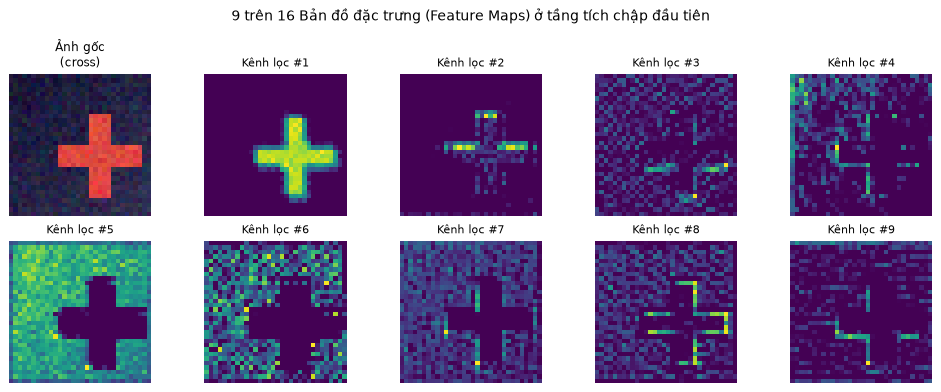

In [3]:
# Cell 3: Trực quan hóa Bản đồ Đặc trưng Trung gian (Feature Maps) của Tầng Tích chập Đầu tiên
cnn_model.eval()
with torch.no_grad():
    sample_input = X_norm[idx_te[:1]].to(device)
    # Lấy đầu ra sau Conv1 + BatchNorm1 + ReLU1
    feat_conv1 = cnn_model.features[:3](sample_input).cpu().numpy()[0]  # shape (16, 32, 32)

fig, axes = plt.subplots(2, 5, figsize=(11, 4.4))
axes[0, 0].imshow(images_np[idx_te[0]])
axes[0, 0].set_title(f"Ảnh gốc\n({class_names[labels_np[idx_te[0]]]})", fontsize=9.5)
axes[0, 0].axis("off")

for i in range(1, 10):
    r, c = divmod(i, 5)
    axes[r, c].imshow(feat_conv1[i - 1], cmap="viridis")
    axes[r, c].set_title(f"Kênh lọc #{i}", fontsize=9)
    axes[r, c].axis("off")
plt.suptitle("9 trên 16 Bản đồ đặc trưng (Feature Maps) ở tầng tích chập đầu tiên", fontsize=11)
plt.tight_layout()
plt.show()


In [4]:
# Cell 4: Thí nghiệm thay đổi một yếu tố — Có BatchNorm2d vs Bỏ BatchNorm2d
class CNNWithoutBN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(64, 4),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

set_seed(42)
no_bn_model = CNNWithoutBN().to(device)
opt_nobn = torch.optim.AdamW(no_bn_model.parameters(), lr=2e-3)
hist_nobn = fit_classifier(no_bn_model, train_loader, val_loader, criterion, opt_nobn, device, epochs=10)

print(f"Có BatchNorm2d -> Best Val Acc (trong 10 epochs): {max(history_cnn['val_acc'][:10])*100:.1f}%")
print(f"Bỏ BatchNorm2d -> Best Val Acc (trong 10 epochs): {max(hist_nobn['val_acc'])*100:.1f}%")


Có BatchNorm2d -> Best Val Acc (trong 10 epochs): 78.6%
Bỏ BatchNorm2d -> Best Val Acc (trong 10 epochs): 61.9%


## 11. Nhận xét cách đọc kết quả
- **Ở Cell 1**: Vùng cảm nhận (`Receptive Field`) tăng từ `3x3` ở `Conv1` lên `14x14` ở `Conv3` nhờ hai tầng `MaxPool2d(2, 2)`. Nhờ đó mỗi điểm đặc trưng ở tầng thứ 3 bao quát được gần một nửa chiều rộng bức ảnh `32x32`.
- **Ở Cell 3**: Các bản đồ đặc trưng (`Feature Maps`) cho thấy mỗi bộ lọc trong 16 kênh đầu tiên tự động chuyên môn hóa: có kênh bật sáng ở viền ngang, có kênh bật sáng ở viền dọc, có kênh bắt vùng lõi màu của hình học.
- **Ở Cell 4**: Khi có `BatchNorm2d`, mô hình hội tụ nhanh và ổn định hơn hẳn trong những epoch đầu tiên.

## 13. Lỗi thường gặp và cách sửa
1. **Nhầm thứ tự kênh `(H, W, C)` khi đưa vào `nn.Conv2d`**: Luôn kiểm tra `x.shape[1] == in_channels`.
2. **Đặt `bias=True` (mặc định) ở `nn.Conv2d` ngay trước `nn.BatchNorm2d`**: Không gây lỗi dừng chương trình nhưng tạo ra các tham số dư thừa không có tác dụng (vì `BatchNorm2d` ngay lập tức trừ đi giá trị trung bình của kênh đó). Hãy đặt `bias=False` ở `Conv2d` khi theo sau là `BatchNorm2d`.

## 14. Bài tập tự làm
- **Cơ bản**: Tính tay kích thước đầu ra của `nn.Conv2d(3, 8, kernel_size=5, stride=2, padding=1, dilation=2)` trên ảnh `(1, 3, 32, 32)` và kiểm tra lại bằng PyTorch.
- **Trung cấp**: So sánh số lượng tham số của tích chập chuẩn `nn.Conv2d(32, 64, kernel_size=3, padding=1)` với tích chập tách chiều **Depthwise Separable Convolution** (`Conv2d(32, 32, 3, padding=1, groups=32)` + `Conv2d(32, 64, 1)`).
- **Nâng cao**: Huấn luyện `ResidualCNN` trong 10 epochs trên cùng `train_loader` và so sánh `val_acc` với `SimpleCNN`.

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 10
# 1. Cơ bản: Kiểm tra công thức tính kích thước đầu ra Conv2d với dilation=2
h_in, p, d, k, s = 32, 1, 2, 5, 2
h_out_formula = (h_in + 2 * p - d * (k - 1) - 1) // s + 1
conv_test = nn.Conv2d(3, 8, kernel_size=k, stride=s, padding=p, dilation=d)
out_tensor = conv_test(torch.zeros(1, 3, 32, 32))
print(f"[Cơ bản] Công thức tính tay H_out = {h_out_formula} | PyTorch thực tế: {tuple(out_tensor.shape)}")
assert h_out_formula == out_tensor.shape[2]

# 2. Trung cấp: So sánh số tham số Standard Conv vs Depthwise Separable Conv (MobileNet style)
std_conv = nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False)
dw_sep_conv = nn.Sequential(
    nn.Conv2d(32, 32, kernel_size=3, padding=1, groups=32, bias=False),  # Depthwise
    nn.Conv2d(32, 64, kernel_size=1, bias=False),                        # Pointwise 1x1
)
p_std = count_parameters(std_conv)["total"]
p_dw = count_parameters(dw_sep_conv)["total"]
print(f"[Trung cấp] Standard Conv params: {p_std:,} vs Depthwise Separable params: {p_dw:,} (Giảm {p_std/p_dw:.1f} lần!)")

# 3. Nâng cao: Huấn luyện ResidualCNN
set_seed(42)
res_net = ResidualCNN(in_channels=3, num_classes=4, base_channels=16).to(device)
opt_res = torch.optim.AdamW(res_net.parameters(), lr=2e-3, weight_decay=1e-4)
hist_res = fit_classifier(res_net, train_loader, val_loader, criterion, opt_res, device, epochs=10)
print(f"[Nâng cao] ResidualCNN Best Val Acc: {hist_res['best_val_acc']*100:.1f}%")


[Cơ bản] Công thức tính tay H_out = 13 | PyTorch thực tế: (1, 8, 13, 13)
[Trung cấp] Standard Conv params: 18,432 vs Depthwise Separable params: 2,336 (Giảm 7.9 lần!)
[Nâng cao] ResidualCNN Best Val Acc: 88.1%


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Hiểu tường tận `Conv2d`, `BatchNorm2d`, `Pooling`, `AdaptiveAvgPool2d`, `ResidualBlock` và `Receptive Field`.
- [x] Đã huấn luyện thành công `SimpleCNN` và `ResidualCNN` kèm lưu checkpoint chuẩn.
- [x] Sẵn sàng chuyển sang **Bài 11: `11_training_validation_and_debugging.ipynb`**.

## 17. Nguồn tham khảo
- LeCun, Y. et al. (1998), *Gradient-Based Learning Applied to Document Recognition*, Proc. IEEE.
- He, K. et al. (2016), *Deep Residual Learning for Image Recognition (ResNet)*, CVPR.
